
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


Dimitriu Eduard, IASD 2602 Ru

## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
FILE = "Human_Activity_Recognition_Using_Smartphones_Data.csv"
path = FILE if os.path.exists(FILE) else os.path.join("..", "materials", FILE)

data = pd.read_csv(path)
print("Размерность:", data.shape)
print("\nТипы данных:")
print(data.dtypes.value_counts())

Размерность: (10299, 562)

Типы данных:
float64    561
str          1
Name: count, dtype: int64


In [2]:
data.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [3]:
print("Пропущенных значений всего:", data.isnull().sum().sum())
print("\nРаспределение классов (Activity):")
print(data["Activity"].value_counts())

Пропущенных значений всего: 0

Распределение классов (Activity):
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


Данные загрузились нормально, 10299 строк и 562 столбца. Почти всё это числа float64, они уже приведены к диапазону от -1 до 1, а текстовый столбец только один, Activity, в нём 6 видов активности. Пропусков нет, и классов примерно поровну.

CSV брал из Seturi de date, как в задании. В архиве те же самые данные, просто уже поделённые на train и test, а тут делить 80/20 надо самому, так что с CSV даже удобнее.


## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

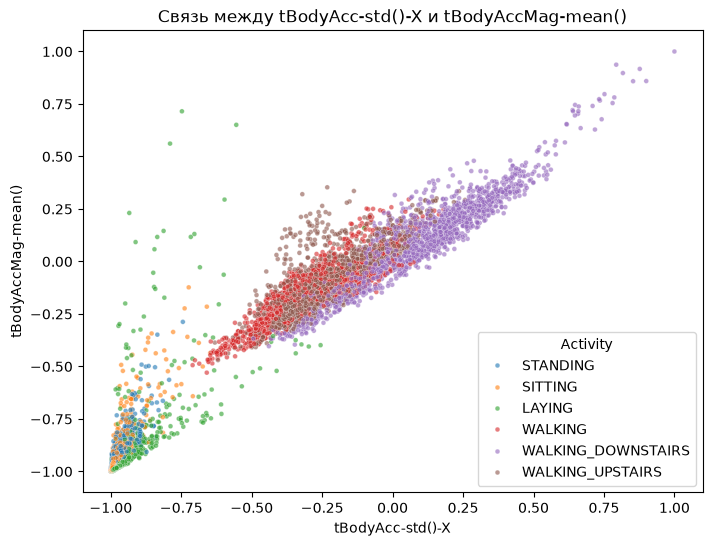

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=data, x="tBodyAcc-std()-X", y="tBodyAccMag-mean()",
                hue="Activity", s=12, alpha=0.6, ax=ax)
ax.set_title("Связь между tBodyAcc-std()-X и tBodyAccMag-mean()")
plt.show()

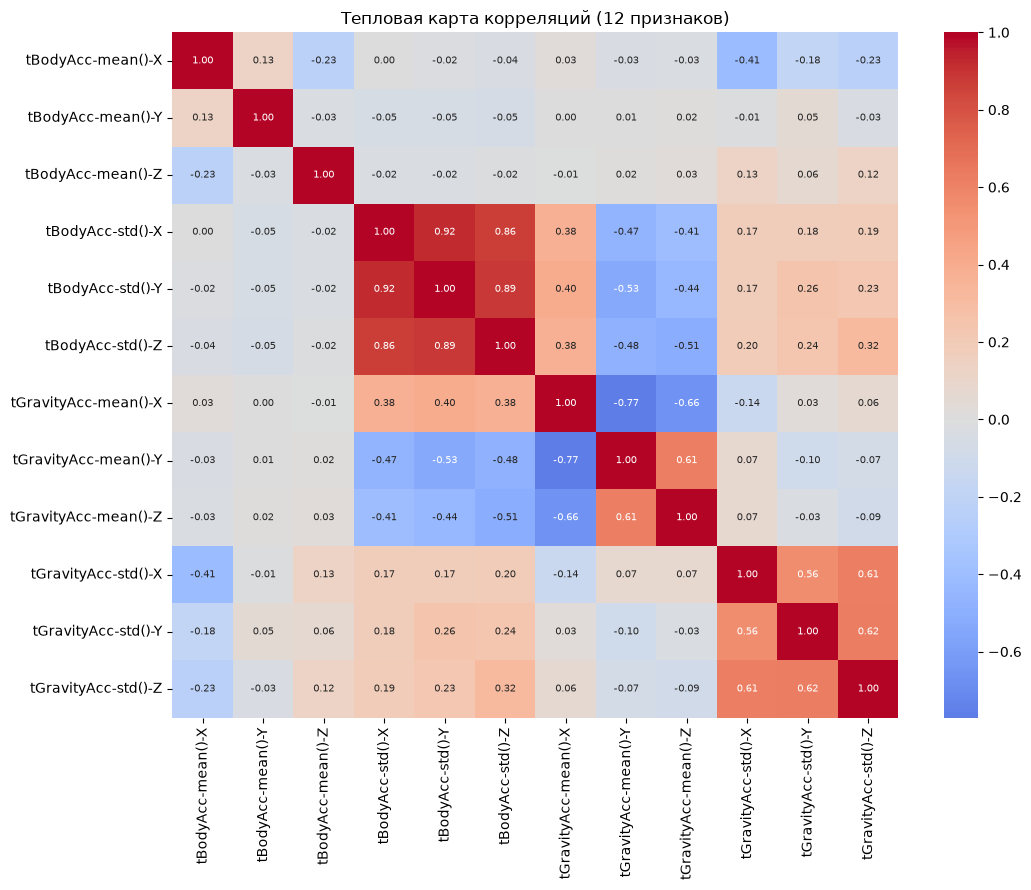

In [5]:
# 561 признак на одной карте нечитаемы, поэтому берём средние и стандартные отклонения сигнала tBodyAcc/tGravityAcc
cols = [c for c in data.columns if c.startswith(("tBodyAcc-mean", "tBodyAcc-std", "tGravityAcc-mean", "tGravityAcc-std"))]
corr = data[cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Тепловая карта корреляций (12 признаков)")
plt.tight_layout()
plt.show()

По графику видно, что когда человек сидит, стоит или лежит, точки собираются внизу слева, ускорение там маленькое. При ходьбе оба значения больше, то есть признаки растут вместе. На тепловой карте std по X, Y и Z сильно коррелируют между собой, многие признаки тут по сути похожи друг на друга.

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Регрессия на числовых данных: предсказываем модуль ускорения тела tBodyAccMag-mean()
# по признакам, полученным из сигнала гироскопа (tBodyGyro*), чтобы не было прямой утечки целевой переменной
target = "tBodyAccMag-mean()"
reg_features = [c for c in data.columns if c.startswith("tBodyGyro-")]

X_reg = data[reg_features]
y_reg = data[target]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", Xr_train.shape, " Test:", Xr_test.shape)

lr = LinearRegression().fit(Xr_train, yr_train)
yr_pred = lr.predict(Xr_test)

mae = mean_absolute_error(yr_test, yr_pred)
mse = mean_squared_error(yr_test, yr_pred)
rmse = np.sqrt(mse)
print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R^2  = {r2_score(yr_test, yr_pred):.4f}")

Train: (8239, 40)  Test: (2060, 40)
MAE  = 0.0674
MSE  = 0.0119
RMSE = 0.1089
R^2  = 0.9456


Для регрессии предсказывал tBodyAccMag-mean(), а в признаки взял только гироскоп, потому что с акселерометром было бы слишком просто, он считает почти то же самое. Ошибки вышли небольшие, MAE примерно 0.07 и R² около 0.95. RMSE чуть больше MAE, значит сильных промахов мало.


## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X = data.drop(columns="Activity")
y = data["Activity"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for k in [3, 5, 7, 9]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    print(f"k={k}: accuracy по фолдам = {np.round(scores, 3)}, среднее = {scores.mean():.4f} ± {scores.std():.4f}")

Train: (8239, 561)  Test: (2060, 561)


k=3: accuracy по фолдам = [0.962 0.953 0.95  0.965 0.956], среднее = 0.9573 ± 0.0058


k=5: accuracy по фолдам = [0.958 0.957 0.953 0.962 0.953], среднее = 0.9565 ± 0.0035


k=7: accuracy по фолдам = [0.959 0.952 0.959 0.959 0.956], среднее = 0.9572 ± 0.0028


k=9: accuracy по фолдам = [0.958 0.953 0.958 0.956 0.954], среднее = 0.9557 ± 0.0019


In [8]:
best_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)).fit(X_train, y_train)
print("KNN (k=7), accuracy на тестовой выборке:", round(best_knn.score(X_test, y_test), 4))

KNN (k=7), accuracy на тестовой выборке: 0.9626



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

Линейная регрессия на тестовой выборке:
  R^2 = 0.9456, RMSE = 0.1089


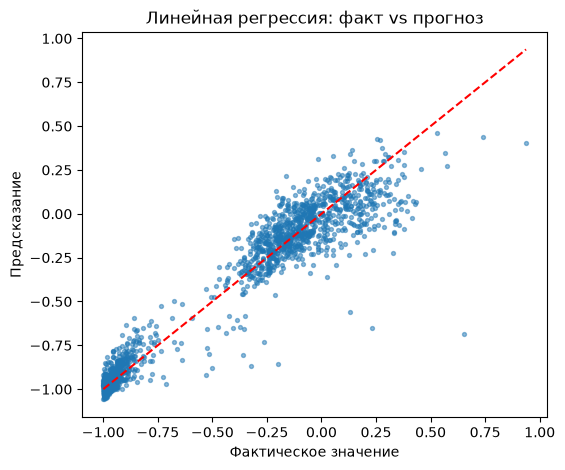

In [9]:
# 5.1 Линейная регрессия (та же задача, что в разделе 3)
print("Линейная регрессия на тестовой выборке:")
print(f"  R^2 = {r2_score(yr_test, yr_pred):.4f}, RMSE = {rmse:.4f}")

plt.figure(figsize=(6, 5))
plt.scatter(yr_test, yr_pred, s=8, alpha=0.5)
lims = [yr_test.min(), yr_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Фактическое значение")
plt.ylabel("Предсказание")
plt.title("Линейная регрессия: факт vs прогноз")
plt.show()

In [10]:
# 5.2 Логистическая регрессия: бинарная задача «динамичная (ходьба) / статичная активность»
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

y_bin = y.str.startswith("WALKING").astype(int)  # 1 = ходьба, 0 = покой
yb_train, yb_test = y_bin.loc[X_train.index], y_bin.loc[X_test.index]

log_bin = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
log_bin.fit(X_train, yb_train)
yb_pred = log_bin.predict(X_test)
print("Accuracy:", round(accuracy_score(yb_test, yb_pred), 4))
print(classification_report(yb_test, yb_pred, target_names=["статичная", "динамичная"]))

Accuracy: 0.9995
              precision    recall  f1-score   support

   статичная       1.00      1.00      1.00      1126
  динамичная       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [11]:
# 5.3 SVM (RBF-ядро) для 6 классов
from sklearn.svm import SVC

svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
print("SVM accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))
print(classification_report(y_test, y_pred_svm))

SVM accuracy: 0.9922
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.98      0.98       356
          STANDING       0.99      0.97      0.98       381
           WALKING       1.00      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      1.00      1.00       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



Логистическую регрессию сделал на задаче «ходит человек или нет», и там почти 100%, это разделяется очень легко. SVM на всех шести классах тоже дал 0.99, путает в основном «сидит» и «стоит», по датчикам они очень похожи.

## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

Логистическая регрессия (6 классов), accuracy: 0.9854


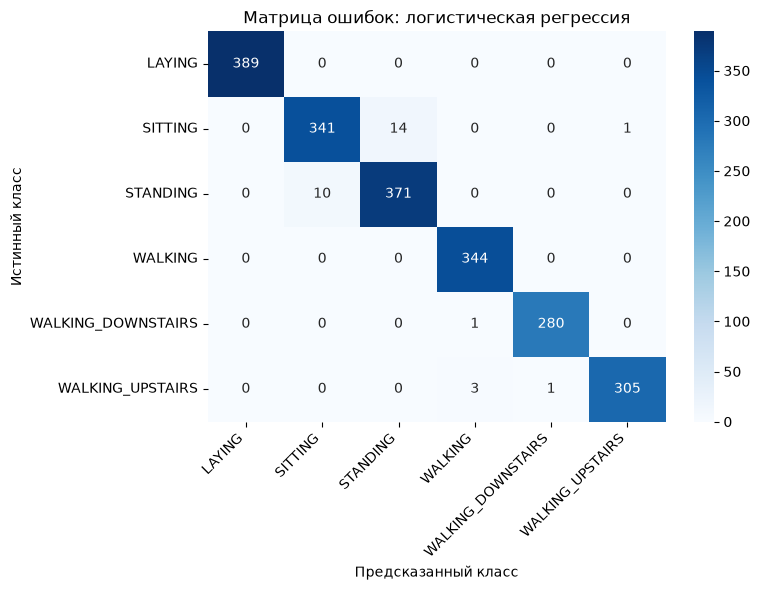

In [12]:
from sklearn.metrics import confusion_matrix

log_multi = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
log_multi.fit(X_train, y_train)
y_pred_log = log_multi.predict(X_test)
print("Логистическая регрессия (6 классов), accuracy:", round(accuracy_score(y_test, y_pred_log), 4))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_log, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок: логистическая регрессия")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Почти всё на диагонали. Ошибки в основном между SITTING и STANDING, человек в обоих случаях не двигается, и телефону трудно понять разницу.


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

theta (градиентный спуск) = 0.96473
theta (аналитически)      = 0.96473
J(theta) в конце          = 0.01118


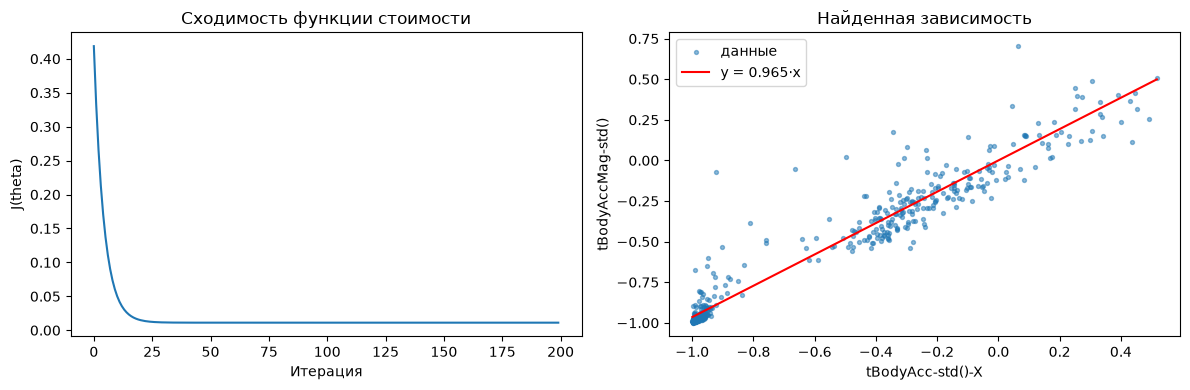

In [13]:
# Подмножество данных: x = tBodyAcc-std()-X, y = tBodyAccMag-std(), 500 случайных строк
sub = data.sample(500, random_state=RANDOM_STATE)
x_gd = sub["tBodyAcc-std()-X"].to_numpy()
y_gd = sub["tBodyAccMag-std()"].to_numpy()

def cost(theta, x, y):
    # J(theta) = (theta*x - y)^2, усреднённая по объектам
    return np.mean((theta * x - y) ** 2)

def gradient(theta, x, y):
    # dJ/dtheta = 2 * x * (theta*x - y)
    return np.mean(2 * x * (theta * x - y))

theta, lr_gd, history = 0.0, 0.1, []
for epoch in range(200):
    theta -= lr_gd * gradient(theta, x_gd, y_gd)
    history.append(cost(theta, x_gd, y_gd))

theta_exact = np.sum(x_gd * y_gd) / np.sum(x_gd ** 2)  # аналитическое решение для проверки
print(f"theta (градиентный спуск) = {theta:.5f}")
print(f"theta (аналитически)      = {theta_exact:.5f}")
print(f"J(theta) в конце          = {history[-1]:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history)
axes[0].set_xlabel("Итерация"); axes[0].set_ylabel("J(theta)"); axes[0].set_title("Сходимость функции стоимости")
axes[1].scatter(x_gd, y_gd, s=8, alpha=0.5, label="данные")
xs = np.linspace(x_gd.min(), x_gd.max(), 100)
axes[1].plot(xs, theta * xs, "r", label=f"y = {theta:.3f}·x")
axes[1].set_xlabel("tBodyAcc-std()-X"); axes[1].set_ylabel("tBodyAccMag-std()"); axes[1].legend()
axes[1].set_title("Найденная зависимость")
plt.tight_layout()
plt.show()

Ошибка падает и потом почти перестаёт меняться. θ получилось такое же, как если посчитать по формуле Σxy / Σx², значит спуск работает правильно.

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Random Forest accuracy: 0.982
tGravityAcc-mean()-X      0.0346
tGravityAcc-min()-X       0.0295
angle(X,gravityMean)      0.0280
tGravityAcc-energy()-X    0.0267
tGravityAcc-mean()-Y      0.0251
dtype: float64


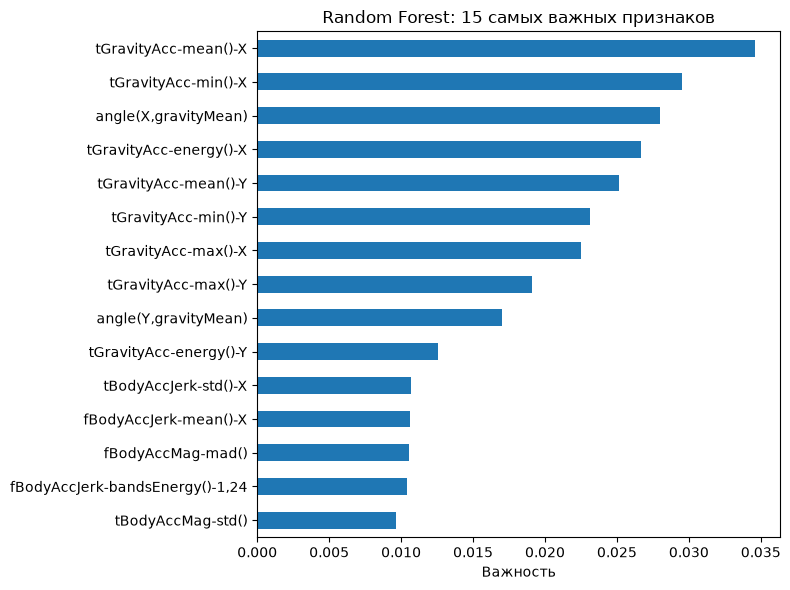

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
print("Random Forest accuracy:", round(rf.score(X_test, y_test), 4))

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(5).round(4))
plt.figure(figsize=(8, 6))
importances.head(15).sort_values().plot(kind="barh")
plt.title("Random Forest: 15 самых важных признаков")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), n_estimators=100,
                         learning_rate=0.5, random_state=RANDOM_STATE)
bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                        random_state=RANDOM_STATE, n_jobs=-1)

results = {}
for name, model in [("AdaBoost", ada), ("Bagging", bag)]:
    model.fit(X_train, y_train)
    results[name] = accuracy_score(y_test, model.predict(X_test))
pd.Series(results, name="accuracy").round(4).to_frame()

,accuracy
AdaBoost,0.9883
Bagging,0.9675


Random Forest больше всего опирается на признаки гравитации (tGravityAcc и угол с gravityMean). По ним понятно, как расположен телефон, а значит лежит человек, сидит или стоит. AdaBoost вышел лучше Bagging, 0.988 против 0.968. Думаю, это потому что бустинг учит каждое новое дерево на ошибках прошлых, а бэггинг просто усредняет.

## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [16]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
        ("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))),
        ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
    ],
    final_estimator=LogisticRegression(max_iter=3000),
    cv=5, n_jobs=-1)
stack.fit(X_train, y_train)
print("Stacking accuracy на тестовой выборке:", round(stack.score(X_test, y_test), 4))

Stacking accuracy на тестовой выборке: 0.9927


In [17]:
summary = pd.Series({
    "KNN (k=7)": best_knn.score(X_test, y_test),
    "Логистическая регрессия": accuracy_score(y_test, y_pred_log),
    "SVM (RBF)": accuracy_score(y_test, y_pred_svm),
    "Random Forest": rf.score(X_test, y_test),
    "AdaBoost": results["AdaBoost"],
    "Bagging": results["Bagging"],
    "Stacking": stack.score(X_test, y_test),
}, name="accuracy").sort_values(ascending=False).round(4)
summary.to_frame()

,accuracy
Stacking,0.9927
SVM (RBF),0.9922
AdaBoost,0.9883
Логистическая регрессия,0.9854
Random Forest,0.9820
Bagging,0.9675
KNN (k=7),0.9626


В итоге лучше всех стекинг и SVM, у обоих около 0.99, логистическая регрессия совсем немного хуже. Хуже всех KNN, 0.96, мне кажется, при 561 признаке расстояния между точками уже мало что значат.


## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
